# WICOS: envelope features (Amin et al., 2019)
This notebook implements the envelope features of

> M. G. Amin, Z. Zeng and T. Shan, "Hand Gesture Recognition based on Radar Micro-Doppler Signature Envelopes," *IEEE RadarConf*, 2019 (`docs/Hand_Gesture_Recognition_based_on_Radar_Micro-Doppler_Signature_Envelopes.pdf`).

**Idea of the paper.** A hand gesture is described by the *outline* of its micro-Doppler signature: the **positive frequency envelope** $e_U(n)$ (the highest velocity towards the radar at time $n$) and the **negative frequency envelope** $e_L(n)$ (the highest velocity away from the radar). According to the paper, these two curves together capture the maximum positive and negative Doppler, the length of the gesture, its bandwidth, and the balance between motion towards and away from the radar. The feature vector is the two curves themselves, $e = [e_U, e_L]$, classified with a 1-nearest-neighbour classifier with the Manhattan (L1) distance.

**The algorithm (Sec. II-B):**
1. Compute the **effective bandwidth** of the gesture spectrum; it defines the maximum positive and negative Doppler.
2. Split the spectrogram into a positive and a negative Doppler half and compute their energy per time bin, $E_U(n)$ and $E_L(n)$ (eq. 2).
3. Scale the energies to thresholds $T_U(n) = \sigma_U E_U(n)$ and $T_L(n) = \sigma_L E_L(n)$ with $\sigma < 1$ (eq. 3). The paper suggests choosing $\sigma$ so that the ratio of energy to threshold is the one found at the maximum Doppler.
4. The envelope at time $n$ is the outermost Doppler bin where the spectrogram is still at or above the threshold.

The functions are in `src/features.py`; `features.extract_features` gives the envelope features stored in the dataset (`src/build_dataset.py`). This notebook first runs every step on **one spectrogram**, then computes the envelopes for **all samples**, and finally classifies them as in the paper. Everything that is checked or chosen here uses the training samples only.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, PredefinedSplit, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sys.path.insert(0, str(Path("../src").resolve()))
import features as F
from build_dataset import GESTURES, SEED, load_data, split

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(exist_ok=True)

spectrograms, metadata = load_data()
idx_train, idx_test, cv_fold = split(metadata)
labels, persons = metadata.label.to_numpy(), metadata.person.to_numpy()
y_train, groups_train = labels[idx_train], persons[idx_train]
doppler = F.doppler_axis()  # Doppler bin of every row of the crop, relative to zero Doppler
EMPIRICAL = ["length", "peak_ratio", "doppler_bandwidth"]  # the paper's T, R and B_w

## Example: one spectrogram, step by step
### Step 0: gesture power
The paper works on the spectrogram $S(n, k)$ of one gesture. We use the **gesture power** $P(d, t)$, i.e. the linear power above the sample's own noise floor inside the Doppler crop (same noise removal as the images, `src/preprocessing.py`), so that pure noise has power 0.

The paper cuts every recording into 1-second windows that each contain one complete gesture. Our recordings have different lengths with silence before and after the gesture, so we keep the **gesture span**: from the first to the last time bin with at least 5% of the power of the strongest time bin.

Sample 607: wave, Person D; 227 time bins, gesture span 26-189 (164 time bins)


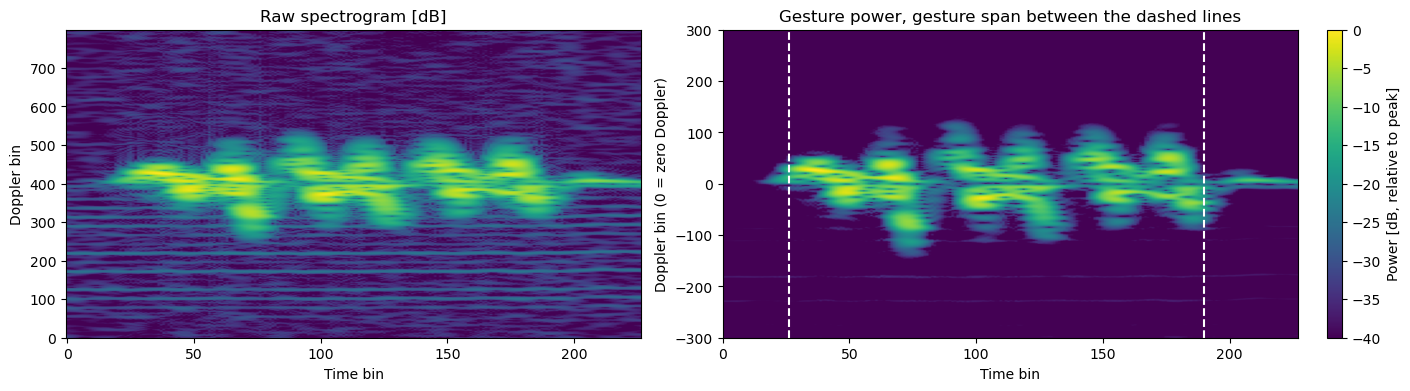

In [2]:
i_ex = idx_train[y_train == 0][0]            # first training wave
x_ex = spectrograms[i_ex]
P_full = F.gesture_power(x_ex)
active = np.flatnonzero(F.active_bins(P_full))
P_ex = F.gesture_span(P_full)
print(f"Sample {i_ex}: {GESTURES[labels[i_ex]]}, Person {persons[i_ex]}; "
      f"{x_ex.shape[1]} time bins, gesture span {active[0]}-{active[-1]} ({P_ex.shape[1]} time bins)")

def show_power(ax, P, title, t0=0):
    """Gesture power in dB relative to its peak (the floor at -40 dB)."""
    im = ax.imshow(10 * np.log10(np.maximum(P / P.max(), 1e-4)), aspect="auto", origin="lower", cmap="viridis",
                   vmin=-40, vmax=0, extent=[t0, t0 + P.shape[1], doppler[0], doppler[-1]])
    ax.set_title(title)
    ax.set_xlabel("Time bin")
    ax.set_ylim(-300, 300)
    return im

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), constrained_layout=True)
axes[0].imshow(x_ex, aspect="auto", origin="lower", cmap="viridis", vmin=-60, vmax=0)
axes[0].set_title("Raw spectrogram [dB]")
axes[0].set_xlabel("Time bin")
axes[0].set_ylabel("Doppler bin")
im = show_power(axes[1], P_full, "Gesture power, gesture span between the dashed lines")
for t in (active[0], active[-1] + 1):
    axes[1].axvline(t, color="white", linestyle="--")
axes[1].set_ylabel("Doppler bin (0 = zero Doppler)")
fig.colorbar(im, ax=axes[1], label="Power [dB, relative to peak]")
plt.show()

### Step 1: effective bandwidth (maximum Doppler)
For each half, the gesture power is summed over time, giving the spectrum of that half. Counting outward from zero Doppler, the **effective bandwidth** ends where 99% of the half's energy is reached (`EFFECTIVE_BANDWIDTH`); that Doppler bin is the maximum positive Doppler $f_p$ and maximum negative Doppler $f_n$ of the gesture. The paper does not say how the effective bandwidth is computed; a fixed energy share is a common choice.

positive half: maximum Doppler +72 bins
negative half: maximum Doppler -90 bins


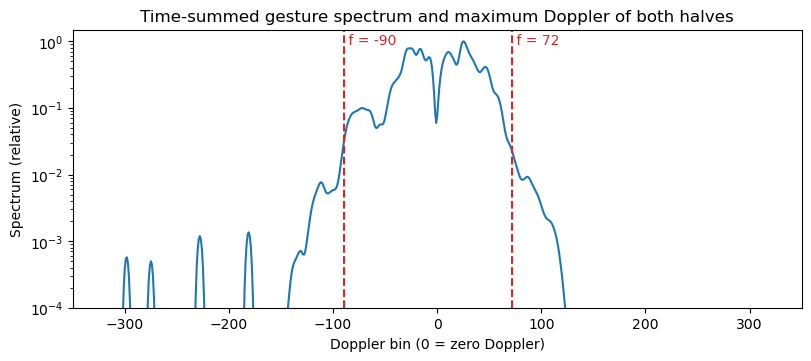

In [3]:
pos, neg = doppler > 0, doppler < 0
halves = {"positive": (P_ex[pos], doppler[pos]), "negative": (P_ex[neg], -doppler[neg])}

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
spectrum = P_ex.sum(axis=1)
ax.plot(doppler, spectrum / spectrum.max(), color="C0")
for name, (P_half, speed) in halves.items():
    k_max = F.effective_bandwidth(P_half, speed)
    f_max = speed[k_max] * (1 if name == "positive" else -1)
    ax.axvline(f_max, color="C3", linestyle="--")
    ax.text(f_max, 0.9, f" f = {f_max}", color="C3")
    print(f"{name:8s} half: maximum Doppler {f_max:+d} bins")
ax.set_yscale("log")
ax.set_ylim(1e-4, 1.5)
ax.set_xlim(-350, 350)
ax.set_xlabel("Doppler bin (0 = zero Doppler)")
ax.set_ylabel("Spectrum (relative)")
ax.set_title("Time-summed gesture spectrum and maximum Doppler of both halves")
plt.show()

### Steps 2 and 3: energy per half and threshold
$E_U(n)$ and $E_L(n)$ are the energies of the positive and negative half in every time bin (eq. 2; the paper squares $S$ there, our $P$ is already a power). The threshold is a fixed fraction of it, $T(n) = \sigma E(n)$ (eq. 3). Following the paper, $\sigma$ is fixed by the time bin and Doppler bin where the maximum Doppler $f_p$ (or $f_n$) occurs: $\sigma = P(f_p, n_p) / E(n_p)$, with $n_p$ the time bin in which $P(f_p, \cdot)$ is largest. In that time bin the threshold therefore lies exactly at the maximum Doppler, and in every other time bin it scales with that time bin's energy.

This per-clip $\sigma$ (`paper_sigma`) varies a lot between clips, so `features.py` uses one fixed value for all clips, `SIGMA` = 0.006: the median of the per-clip values over both halves of the training clips. Below both thresholds are shown.

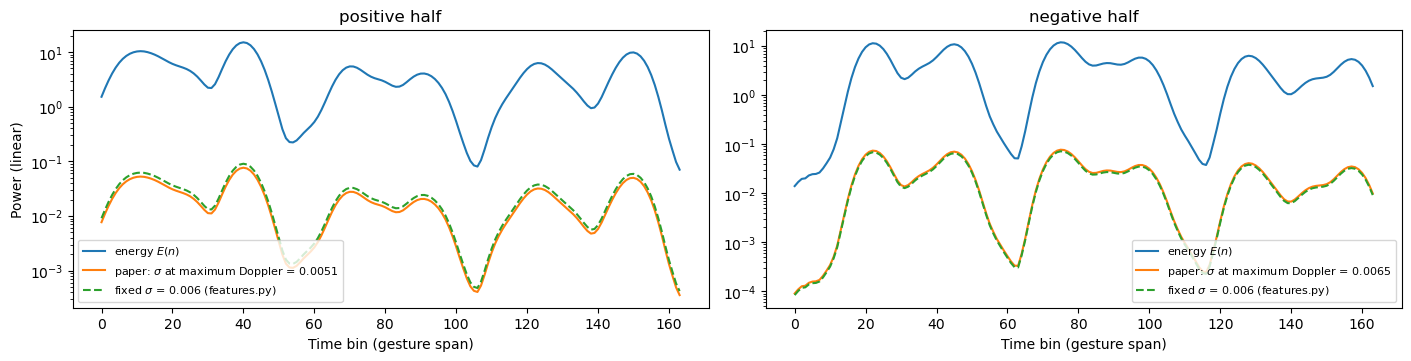

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), constrained_layout=True)
sigmas = {}
for ax, (name, (P_half, speed)) in zip(axes, halves.items()):
    E = P_half.sum(axis=0)
    sigmas[name] = F.paper_sigma(P_half, speed)
    ax.plot(E, label="energy $E(n)$")
    ax.plot(sigmas[name] * E, label=f"paper: $\\sigma$ at maximum Doppler = {sigmas[name]:.4f}")
    ax.plot(F.SIGMA * E, linestyle="--", label=f"fixed $\\sigma$ = {F.SIGMA} (features.py)")
    ax.set_yscale("log")
    ax.set_title(f"{name} half")
    ax.set_xlabel("Time bin (gesture span)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Power (linear)")
plt.show()

### Step 4: the envelope
In every time bin, the envelope is the outermost Doppler bin whose power is still at or above the threshold (fixed $\sigma$ = `SIGMA`). Below: one time bin (left) and the envelopes over the whole gesture (right).

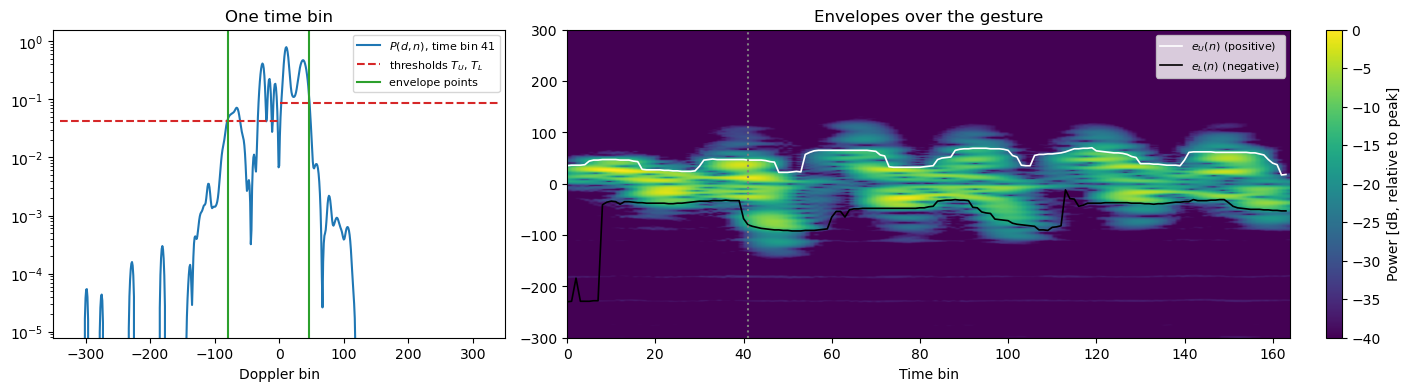

In [5]:
upper, lower = F.envelopes(P_ex, doppler)
n_show = np.argmax(P_ex.sum(axis=0))         # the strongest time bin

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), constrained_layout=True, gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
ax.plot(doppler, P_ex[:, n_show], color="C0", label=f"$P(d, n)$, time bin {n_show}")
for mask, e in ((pos, upper), (neg, lower)):
    T = F.SIGMA * P_ex[mask, n_show].sum()
    ax.hlines(T, *(doppler[mask][[0, -1]]), color="C3", linestyle="--")
    ax.axvline(e[n_show], color="C2")
ax.plot([], [], color="C3", linestyle="--", label="thresholds $T_U$, $T_L$")
ax.plot([], [], color="C2", label="envelope points")
ax.set_yscale("log")
ax.set_ylim(P_ex[:, n_show].max() * 1e-5, P_ex[:, n_show].max() * 2)
ax.set_xlim(-350, 350)
ax.set_xlabel("Doppler bin")
ax.set_title("One time bin")
ax.legend(fontsize=8)

im = show_power(axes[1], P_ex, "Envelopes over the gesture")
axes[1].plot(upper, color="white", linewidth=1.2, label="$e_U(n)$ (positive)")
axes[1].plot(lower, color="black", linewidth=1.2, label="$e_L(n)$ (negative)")
axes[1].axvline(n_show, color="gray", linestyle=":")
axes[1].legend(fontsize=8, loc="upper right")
fig.colorbar(im, ax=axes[1], label="Power [dB, relative to peak]")
plt.show()

### Step 5: the feature vector
The paper concatenates the two envelopes, $e = [e_U, e_L]$. Its samples all have the same length (1-second windows), ours do not, so each envelope is **resampled to 16 points** over the gesture span (`ENVELOPE_POINTS`), giving 32 features. The resampling removes the gesture length, so the paper's three **empirical features** (Sec. IV-A, its baseline) are computed as well: the length $T = t_e - t_s$, the ratio of the peak frequencies $R = |f_p / f_n|$ and the bandwidth $B_w = |f_p| + |f_n|$.

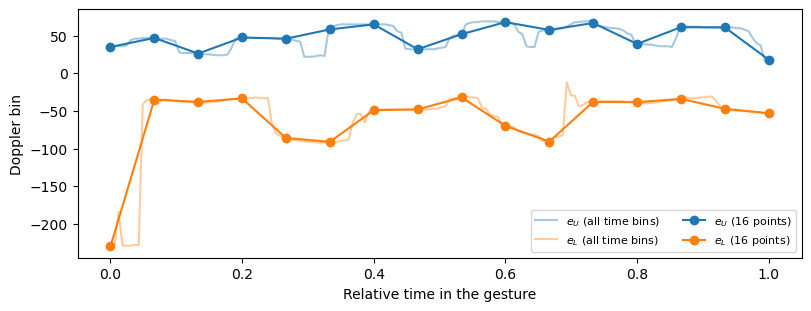

Feature vector: 32 values; empirical features: {'length': 164, 'peak_ratio': np.float64(0.8), 'doppler_bandwidth': np.int64(162)}


In [6]:
def envelope_vector(x, sigma=F.SIGMA):
    """e = [e_U, e_L] (ENVELOPE_POINTS each) and the empirical features T, R, B_w of one spectrogram."""
    f = F.extract_features(x, sigma=sigma)
    return np.array([v for k, v in f.items() if k.startswith("env_")]), {k: f[k] for k in EMPIRICAL}

vector, empirical = envelope_vector(x_ex)

fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
t = np.linspace(0, 1, P_ex.shape[1])
ax.plot(t, upper, color="C0", alpha=0.4, label="$e_U$ (all time bins)")
ax.plot(t, lower, color="C1", alpha=0.4, label="$e_L$ (all time bins)")
t16 = np.linspace(0, 1, F.ENVELOPE_POINTS)
ax.plot(t16, vector[:F.ENVELOPE_POINTS], "o-", color="C0", label="$e_U$ (16 points)")
ax.plot(t16, vector[F.ENVELOPE_POINTS:], "o-", color="C1", label="$e_L$ (16 points)")
ax.set_xlabel("Relative time in the gesture")
ax.set_ylabel("Doppler bin")
ax.legend(fontsize=8, ncol=2)
plt.show()

print(f"Feature vector: {vector.shape[0]} values; empirical features: {empirical}")

## All samples
The same steps for every spectrogram (training and test: the method only uses the sample itself and fixed constants, so there is no leakage).

Envelope features: (960, 32), empirical features: (960, 3)


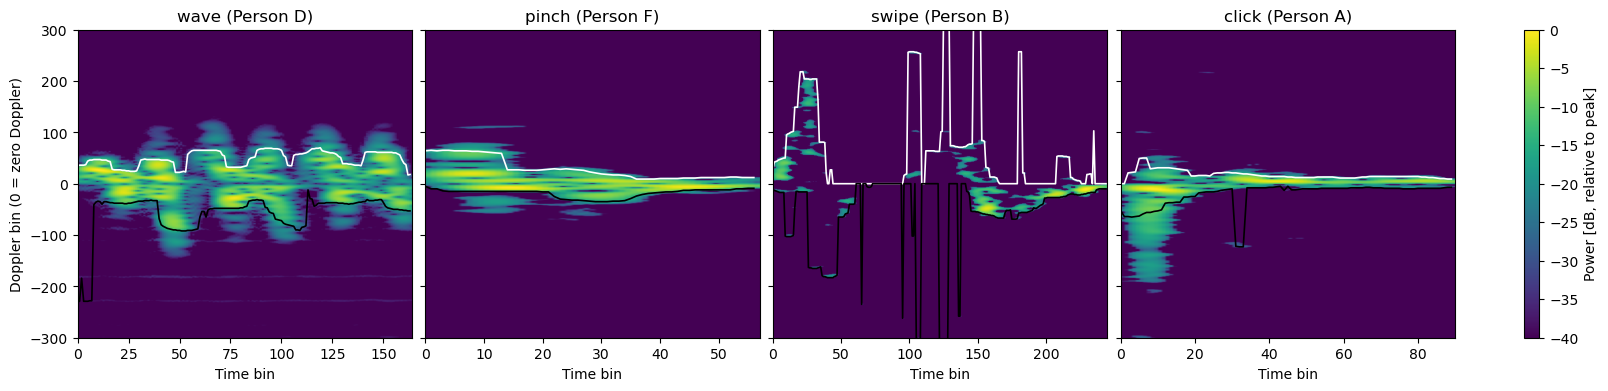

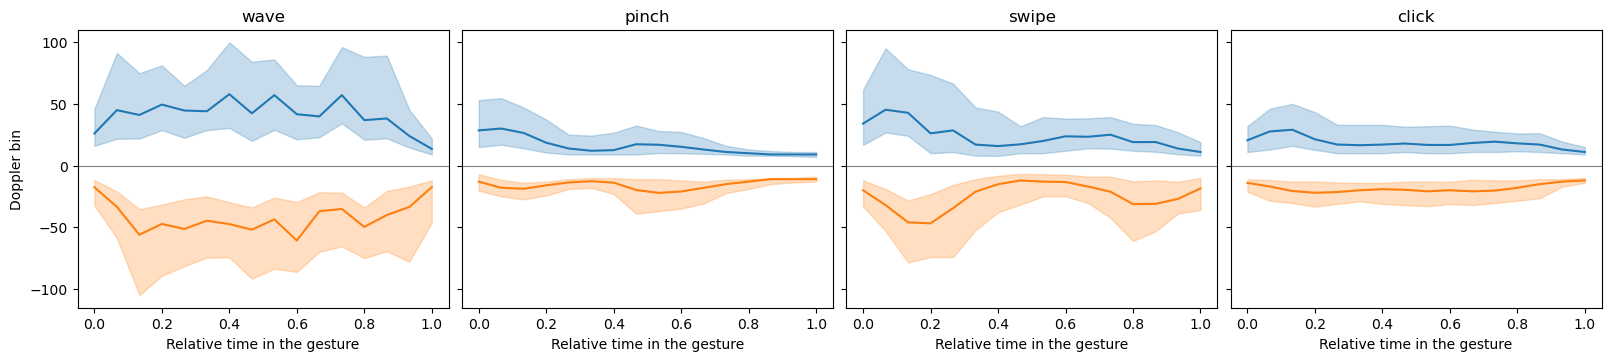

In [7]:
feats = pd.DataFrame([F.extract_features(x) for x in spectrograms])   # as in build_dataset.py
X_env = feats.filter(like="env_").to_numpy()                    # (960, 32): e_U and e_L, 16 points each
X_emp = feats[EMPIRICAL]                                        # (960, 3): T, R, B_w
print(f"Envelope features: {X_env.shape}, empirical features: {X_emp.shape}")

# The envelopes of one training sample per gesture
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True, constrained_layout=True)
for ax, k in zip(axes, range(len(GESTURES))):
    i = idx_train[y_train == k][0]
    P = F.gesture_span(F.gesture_power(spectrograms[i]))
    up, lo = F.envelopes(P, doppler)
    im = show_power(ax, P, f"{GESTURES[k]} (Person {persons[i]})")
    ax.plot(up, color="white", linewidth=1.2)
    ax.plot(lo, color="black", linewidth=1.2)
axes[0].set_ylabel("Doppler bin (0 = zero Doppler)")
fig.colorbar(im, ax=axes, label="Power [dB, relative to peak]")
fig.savefig(FIG_DIR / "amin_envelopes_examples.pdf", bbox_inches="tight")
plt.show()

# Average envelope per gesture over the training samples (median and 25-75% band)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True, constrained_layout=True)
for ax, k in zip(axes, range(len(GESTURES))):
    E = X_env[idx_train][y_train == k]
    for part, color in ((slice(0, F.ENVELOPE_POINTS), "C0"), (slice(F.ENVELOPE_POINTS, None), "C1")):
        ax.plot(t16, np.median(E[:, part], axis=0), color=color)
        ax.fill_between(t16, *np.percentile(E[:, part], [25, 75], axis=0), color=color, alpha=0.25)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(GESTURES[k])
    ax.set_xlabel("Relative time in the gesture")
axes[0].set_ylabel("Doppler bin")
fig.savefig(FIG_DIR / "amin_envelopes_per_gesture.pdf", bbox_inches="tight")
plt.show()

**Interpretation.**
- In clean recordings the envelopes follow the motion: the wave swings between about +70 and -90 Doppler bins, the click shows one short excursion to strongly negative Doppler. On average (bottom figure) the wave has the largest and most constant envelopes, pinch and swipe start wide and narrow towards the end, and the click stays narrow.
- The envelopes do **not** follow the outer edge of the signature but a level inside it: the threshold is a fixed fraction $\sigma$ of the energy of each time bin.
- **The envelopes are noisy in weak time bins.** In a time bin with little gesture energy, the threshold $\sigma E(n)$ is very low, so a single noise cell that survived the noise floor far from zero Doppler becomes "the" envelope. This is clearly visible in the swipe of Person B (the noisiest person) and in the click: spikes to ±200-300 bins. The spread between samples of the same gesture (bands) is therefore large.

## Classification as in the paper
The paper classifies the envelope vector with a 1-nearest-neighbour classifier (k = 1) with the Manhattan (L1) or Euclidean (L2) distance, and with an SVM; its empirical features with 1-NN (L1). It reports 95.2% (kNN-L1), 93.9% (kNN-L2) and 83.1% (SVM) for the envelopes and 68% for the empirical features, on a random 70/30 split of its own data (5 gesture classes, 4 persons).

We evaluate the same classifiers on the training set with the 5 CV folds and with LOSO (new person), plus a random forest as in the other model notebooks. The envelopes are all in Doppler bins, so they are not scaled (as in the paper); the empirical features have different units, so they are standardised.

In [8]:
cv5, loso = PredefinedSplit(cv_fold[idx_train]), LeaveOneGroupOut()

def evaluate(make_model, X):
    X = np.asarray(X)[idx_train]
    return {"5-fold": cross_val_score(make_model(), X, y_train, cv=cv5).mean(),
            "LOSO": cross_val_score(make_model(), X, y_train, cv=loso, groups=groups_train).mean()}

knn_l1 = lambda: KNeighborsClassifier(n_neighbors=1, metric="manhattan")
knn_l2 = lambda: KNeighborsClassifier(n_neighbors=1, metric="euclidean")
svm = lambda: make_pipeline(StandardScaler(), SVC())
rf = lambda: RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

paper = pd.DataFrame({
    ("envelopes", "kNN-L1 (paper)"): evaluate(knn_l1, X_env),
    ("envelopes", "kNN-L2"): evaluate(knn_l2, X_env),
    ("envelopes", "SVM"): evaluate(svm, X_env),
    ("envelopes", "random forest"): evaluate(rf, X_env),
    ("empirical (T, R, Bw)", "kNN-L1 (paper)"): evaluate(lambda: make_pipeline(StandardScaler(), knn_l1()), X_emp),
    ("empirical (T, R, Bw)", "random forest"): evaluate(rf, X_emp),
    ("envelopes + empirical", "random forest"): evaluate(rf, np.hstack([X_env, X_emp])),
}).T
display(paper.round(3))

5-fold   LOSO
envelopes             kNN-L1 (paper)   0.813  0.484
                      kNN-L2           0.736  0.470
                      SVM              0.737  0.560
                      random forest    0.836  0.608
empirical (T, R, Bw)  kNN-L1 (paper)   0.701  0.487
                      random forest    0.750  0.491
envelopes + empirical random forest    0.908  0.689

**Results.**
- The paper's method reaches **0.81 (5-fold) and 0.48 (LOSO) with kNN-L1**, well below the 95% of the paper. As in the paper, L1 is better than L2 (0.81 vs 0.74), and kNN-L1 beats the SVM on 5-fold CV (not on LOSO). A random forest uses the envelopes best (0.84 / 0.61).
- The empirical features alone give 0.70 with kNN-L1, close to the paper's 68%. **Envelopes and empirical features together** are clearly better than either alone (random forest 0.91 / 0.69): the resampling removes the gesture length, and the length is one of the most informative properties of DopNet gestures.

**Why so much lower than the paper?**
1. **Noise.** The outermost-cell rule reacts to single noise cells in weak time bins (see above). The paper's gestures were recorded 20 cm from the radar in 1-second windows that contain one gesture each; DopNet recordings are longer, with weak parts inside the gesture and a much noisier person (B).
2. **Evaluation.** The paper uses a random 70/30 split of 4 persons; our 5-fold CV is the comparable number (0.81). LOSO asks for a new person, which is much harder for a nearest-neighbour classifier on raw curves: everyone makes the gesture at a slightly different speed and amplitude.
3. **Different gestures.** The paper's 5 classes were formed by grouping 15 gestures with very different signatures; DopNet's pinch and click are both small finger movements close to zero Doppler, whose envelopes are similar (bottom figure).

## Sensitivity: the threshold and the envelope definition
The paper says $\sigma$ "can be chosen empirically", and proposes the ratio at the maximum Doppler as an effective choice. We compare the fixed `SIGMA` with the paper's per-clip choice, with other fixed values of $\sigma$, and with a cumulative definition: the Doppler bin where the cumulative power of the whole time bin reaches 5% (lower) and 95% (upper envelope), which does not look at single cells but at the power distribution. Same 16 points per envelope, training set only.

In [9]:
def paper_vector(x, n=F.ENVELOPE_POINTS):
    """Envelopes with the paper's per-clip sigma (paper_sigma), separately per half."""
    P = F.gesture_span(F.gesture_power(x))
    curves = []
    for sign, (P_half, speed) in zip((1, -1), F.halves(P, doppler)):
        e = F.half_envelope(P_half, speed, F.paper_sigma(P_half, speed))  # sigma nan (empty half) -> envelope 0
        curves.append(sign * F.resample(e, n))
    return np.concatenate(curves)

def cumulative_vector(x, n=F.ENVELOPE_POINTS, levels=(0.95, 0.05)):
    """Envelopes where the cumulative power of the time bin reaches 95% (upper) and 5% (lower)."""
    P = F.gesture_span(F.gesture_power(x))
    has_power = P.sum(axis=0) > 0                    # time bins without any power get envelope 0 (as in the paper method)
    cum = np.cumsum(P[:, has_power], axis=0) / P[:, has_power].sum(axis=0)
    curves = []
    for level in levels:
        e = np.zeros(P.shape[1])
        e[has_power] = doppler[np.argmax(cum >= level, axis=0)]
        curves.append(F.resample(e, n))
    return np.concatenate(curves)

train_specs = [spectrograms[i] for i in idx_train]
variants = {f"fixed sigma = {F.SIGMA} (features.py)": X_env[idx_train],
            "paper: per-clip sigma at maximum Doppler": np.stack([paper_vector(x) for x in train_specs])}
for sigma in (0.002, 0.02, 0.1):
    variants[f"fixed sigma = {sigma}"] = np.stack([envelope_vector(x, sigma)[0] for x in train_specs])
variants["cumulative power 5% / 95%"] = np.stack([cumulative_vector(x) for x in train_specs])

def evaluate_train(make_model, X):  # X already restricted to the training samples
    return {"5-fold": cross_val_score(make_model(), X, y_train, cv=cv5).mean(),
            "LOSO": cross_val_score(make_model(), X, y_train, cv=loso, groups=groups_train).mean()}

sensitivity = pd.concat({name: pd.DataFrame({"kNN-L1": evaluate_train(knn_l1, X), "random forest": evaluate_train(rf, X)}).T.stack()
                         for name, X in variants.items()}, axis=1).T
display(sensitivity.round(3))

kNN-L1        random forest       
                                         5-fold   LOSO        5-fold   LOSO
fixed sigma = 0.006 (features.py)         0.813  0.484         0.836  0.608
paper: per-clip sigma at maximum Doppler  0.806  0.456         0.814  0.535
fixed sigma = 0.002                       0.846  0.504         0.848  0.582
fixed sigma = 0.02                        0.781  0.492         0.801  0.618
fixed sigma = 0.1                         0.648  0.477         0.764  0.505
cumulative power 5% / 95%                 0.893  0.560         0.875  0.663

**Results.**
- The paper's **per-clip** $\sigma$ is slightly worse than a fixed one (kNN-L1 LOSO 0.46 vs 0.48 for `SIGMA` = 0.006). Among the fixed values, a lower $\sigma$ helps kNN-L1 a little (0.002: 0.85 / 0.50) and only $\sigma$ = 0.1 is clearly worse; all stay in the same range: the per-cell threshold itself is the weak point, not the exact value of $\sigma$.
- The **cumulative-power definition** is the best for kNN-L1 (0.89 / 0.56) and the random forest (0.88 / 0.66). It looks at the power *distribution* of a whole time bin instead of the single outermost cell above a threshold, so one noise cell hardly moves it.

## Conclusion
- The envelope method of Amin et al. (2019) is implemented as described in the paper (Sec. II-B): effective bandwidth, energy per half, threshold $\sigma E(n)$, outermost cell above the threshold, and $e = [e_U, e_L]$ classified with kNN-L1. The adaptations are the gesture span and the resampling to 16 points, because DopNet recordings have different lengths, and one fixed $\sigma$ (the median of the paper's per-clip choice) instead of a per-clip value.
- On DopNet it works worse than in the paper (kNN-L1: 0.81 5-fold, 0.48 LOSO, vs 95%), mainly because the outermost-cell rule is sensitive to noise cells in weak time bins and because the curves alone lose the gesture length.
- `features.extract_features` (the features in the dataset) therefore combines the envelope curves with the empirical features $T$, $R$, $B_w$: random forest 0.91 / 0.69. An envelope defined by the **cumulative power** is more robust than the paper's threshold and is a candidate for a later version of `features.py`.